In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d


from scipy import optimize as opt
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


ModuleNotFoundError: No module named 'GenPaths'

In [2]:
######## High level Fitting Functions ########
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = True, dh = None):
    # to use later
    if smoothSigma is not None and smoothSigma != 0:
        theseArgsDict = locals()
        del theseArgsDict["wlen"]
        theseArgsDict["smoothSigma"] = None

    photon = PhotonInfo(wlen, theta1, dataHelper=dh)    
    Ttotal = photon.T_total_windowAndOxide(tOxide)
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        # nyield = (380/wlen)
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, np.sqrt(cutinWl/wlen), 1)
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    # do 1 recursive call here
    if (smoothSigma is not None) and (smoothSigma != 0): # expensive but simple/works/robust
        NperSigma = 5
        stepSize = smoothSigma / NperSigma
        NsigmaPast = 3
        newXVals = np.arange(min(wlen)-NsigmaPast*smoothSigma, max(wlen) + NsigmaPast*smoothSigma + stepSize, stepSize) # for full array at once. requires interp1d below
        fullerPDEVals = PDE_allArgs(wlen=newXVals, **theseArgsDict) # WASN'T RECURSIVELY PASSING dh BEFORE
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=NperSigma) # this sigma argument is saying 'how many X points correspond to 1sigma'
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)     
        
    return PDE

In [3]:
peVdict = {1: (0.2611, 0.0017), 2: (0.5649, 0.0048), 3: (0.7494, 0.0046), 4: (0.84, 0.0049), 5: (0.9164, 0.0054), 6: (0.9386, 0.0062), 7: (0.9427, 0.0071)}
phVdict = {1: (0.0525, 0.0007), 2: (0.153, 0.0022), 3: (0.2502, 0.0023), 4: (0.3292, 0.0026), 5: (0.3789, 0.0029), 6: (0.4305, 0.0035), 7: (0.4821, 0.0042)}

-----------------------------
Silicon data from
   ../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
../o

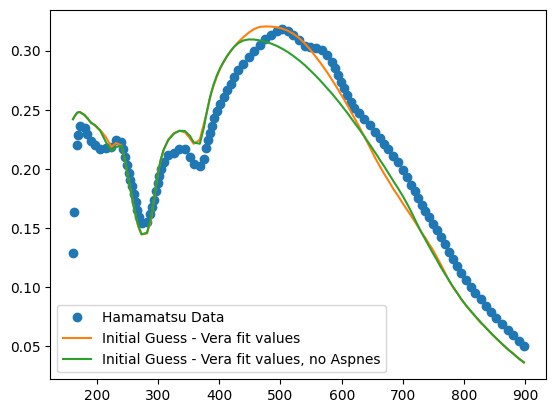

In [4]:
# do this first to avoid any confusion with singleton class
dhAspnes = OpticsData(siDataPath="../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt")

hamxF, hamyF = OpticsData().Load_Ham_data(fname = "HamVUV4_6050CQ-02_fromDatasheet.txt")
hamCut = 160
hamx = hamxF[hamxF > hamCut]
hamy = hamyF[hamxF > hamCut]

print(dhAspnes.mPathSi)

parBoring = {"FF":0.6, "quantum":True, 'smoothSigma': None, "dh":dhAspnes}
parBoring_standard = parBoring.copy()
parBoring_standard["dh"] = None

fixedPars_fromFits = {'tOxide': 16.5, 'dp_star': 1.15, "Xpn":1500, "dw_star":6.6e3}
fullFixed_dict = {**fixedPars_fromFits, **parBoring}

VtoGuess = 5
floatPars = {"pe":peVdict[VtoGuess][0], "ph": phVdict[VtoGuess][0]}
floatBounds = {"pe":(0,1.1), "ph":(0,1.1)}

# this is from the 'enforce harry' crazy fit that probes p++
# fixedPars_fromFits = {'dp_star': 1.3239, 'Xpn': 4.988, 'dw_star': 2900.903, 'tOxide': 16.5, 'FF': 0.6, 'quantum': True, 'smoothSigma': None}
# floatPars = {"pe":1, "ph":1}

plt.plot(hamx, hamy, 'o', label='Hamamatsu Data')
yInput = PDE_allArgs(hamx, theta1=0, **fixedPars_fromFits, **floatPars, **parBoring)
plt.plot(hamx, yInput, label='Initial Guess - Vera fit values')

yInput_standard = PDE_allArgs(hamx, theta1=0, **fixedPars_fromFits, **floatPars, **parBoring_standard)
plt.plot(hamx, yInput_standard, label='Initial Guess - Vera fit values, no Aspnes')
plt.legend()

In [5]:
hamErrorFrac = 0.05
hamYerr = np.repeat(0.01, len(hamy))
dataObj = [{"wlen":hamx, "yVals":hamy, "yErrs":hamYerr, "theta1":0}]

x0, x0Name = SS.BuildX0(floatPars, PDE_allArgs)
print(x0)
x0Bounds = SS.BuildX0_bounds(floatBounds, PDE_allArgs)

a = SS.GenericResiduals(x0=x0, dataObj=dataObj, functionToFit=PDE_allArgs, fixedArgs_dict=fullFixed_dict,
                    verbose=True, yNames=("yVals", "yErrs"))
print("score:", a)

[0.9164, 0.3789]
------- GenericResiduals(function=PDE_allArgs) -------
	all input parameters (except data):  ['FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
	floating args:  ['pe', 'ph']
	---------------- data block 0 --------------------
		float dict (from x0): {'pe': 0.9164, 'ph': 0.3789}
		fixed dict: {'tOxide': 16.5, 'dp_star': 1.15, 'Xpn': 1500, 'dw_star': 6600.0, 'FF': 0.6, 'quantum': True, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x15d1abcd0>}
		dataDict for function, (keys): {'wlen': [161.2456, 163.3947, 167.0164, '...'], 'theta1': 0}
		dataDict for data (y): {'yVals': [0.129, 0.1637, 0.22, '...'], 'yErrs': [0.01, 0.01, 0.01, '...']}
	----------------
score: 559.2438559923104


In [6]:
fitResult = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fullFixed_dict, dataObj, PDE_allArgs), method='migrad')

print(fitResult)
resPdict = SS.GetResDict(fitResult, x0Name)
print("score:", fitResult.fun)
print(resPdict)

  message: Optimization terminated successfully.
  success: True
      fun: 254.92571849878584
        x: [ 8.578e-01  5.604e-01]
 hess_inv: ┌────┬─────────────────────┐
           │    │        x0        x1 │
           ├────┼─────────────────────┤
           │ x0 │  1.27e-05 -0.011e-3 │
           │ x1 │ -0.011e-3  5.86e-05 │
           └────┴─────────────────────┘
     nfev: 45
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 254.9                      │              Nfcn = 45               │
           │ EDM = 5.53e-11 (Goal: 0.0001)    │                                      │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below EDM threshold (goal x 10)

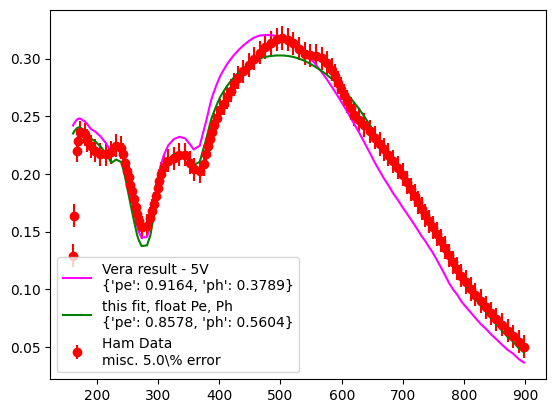

In [7]:
yFit = PDE_allArgs(hamx, theta1=0, **fullFixed_dict, **resPdict)

plt.errorbar(hamx, hamy, yerr=hamYerr, linestyle="None", marker='o', color="red", label=f'Ham Data\nmisc. {hamErrorFrac*100}\% error')

plt.plot(hamx, yInput, color="magenta", label=f'Vera result - {VtoGuess:d}V\n'+str(floatPars))
plt.plot(hamx, yFit, color="green", label='this fit, float Pe, Ph\n' + str(resPdict))

# plt.xlim(140, 170)
plt.legend()
plt.show()

---
---
### Try floating everything!

In [8]:
dataObj = [{"wlen":hamx, "yVals":hamy, "yErrs":hamErrorFrac*hamy, "theta1":0}]

fixedPars_global = { **parBoring}
print("fixed inputs:", fixedPars_global)

floatPars_global = {'tOxide': 16.5, 'dp_star': 1.15, "Xpn":1330, "dw_star":7e3, "pe":0.95, "ph":0.45}

floatBounds_global_pickFrom = {'tOxide': (0.5, 50), 'dp_star': (0.5, 50), 'Xpn': (1e3, 5e3), 'dw_star': (5e3, 30e3),  "pe":(0,1.1), "ph":(0,1.1)}

# avoid rewriting the bounds every time
floatBounds_global = {key:item for key, item in floatBounds_global_pickFrom.items() if key in floatPars_global.keys()}

# id like to show which parameters free help the fit the most, by plotting the reduced score as a function of each parameter

x0, x0Name = SS.BuildX0(floatPars_global, PDE_allArgs)
x0Bounds = SS.BuildX0_bounds(floatBounds_global, PDE_allArgs)

SS.GenericResiduals(x0=x0, dataObj=dataObj, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_global,
                    verbose=True, yNames=("yVals", "yErrs"))

fitResult_global = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fixedPars_global, dataObj, PDE_allArgs), method='migrad')

print(fitResult_global)
resPdict_global = SS.GetResDict(fitResult_global, x0Name)
resDictErrors_global = SS.GetResErrorDict(fitResult_global, x0Name)

print("score:", fitResult_global.fun)
print("global resutl dict:\n", resPdict_global)
print(resDictErrors_global)

fixed inputs: {'FF': 0.6, 'quantum': True, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x15d1abcd0>}
------- GenericResiduals(function=PDE_allArgs) -------
	all input parameters (except data):  ['FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
	floating args:  ['tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph']
	---------------- data block 0 --------------------
		float dict (from x0): {'tOxide': 16.5, 'dp_star': 1.15, 'Xpn': 1330, 'dw_star': 7000.0, 'pe': 0.95, 'ph': 0.45}
		fixed dict: {'FF': 0.6, 'quantum': True, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x15d1abcd0>}
		dataDict for function, (keys): {'wlen': [161.2456, 163.3947, 167.0164, '...'], 'theta1': 0}
		dataDict for data (y): {'yVals': [0.129, 0.1637, 0.22, '...'], 'yErrs': [0.006450000000000001, 0.008185000000000001, 0.011000000000000001, '...']}
	----------------
  message: Optimization terminated successfully.
  su

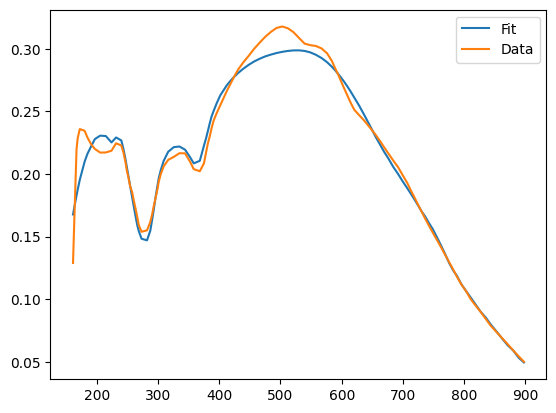

In [9]:
yFit = PDE_allArgs(hamx, theta1=0, **fixedPars_global, **resPdict_global)

plt.plot(hamx, yFit, label='Fit')
plt.plot(hamx, hamy, label='Data')
# plt.vlines(176, 0, max(hamy))
plt.legend()

---
### Sequential Fitting

In [10]:
## Doing Fits sequentially

## UV fit
UVlim = 420
UVx = hamx[hamx < UVlim]
UVy = hamy[hamx < UVlim]
dataObj_UV = [{"wlen":UVx, "yVals":UVy, "yErrs":hamErrorFrac*UVy, "theta1":0}]

fixedPars_UV = {"ph":0.0, "Xpn":1330, "dw_star":7e3, **parBoring}
print("UV fixed:", fixedPars_UV)

floatPars_UV = {"tOxide":16.5, 'dp_star': 1.15, "pe":0.95}
floatBound_UV = {"tOxide":(5, 50), 'dp_star': (0.1, 50), "pe":(0,1.1)}

x0, x0Name = SS.BuildX0(floatPars_UV, PDE_allArgs)
x0Bounds = SS.BuildX0_bounds(floatBound_UV, PDE_allArgs)
fitR_UV = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fixedPars_UV, dataObj_UV, PDE_allArgs), method='migrad')

print(fitR_UV)
resDict_UV = SS.GetResDict(fitR_UV, x0Name)
resDict_UV_errors = SS.GetResErrorDict(fitR_UV, x0Name)
print("score:", fitR_UV.fun)
print(resDict_UV)
print(resDict_UV_errors)


UV fixed: {'ph': 0.0, 'Xpn': 1330, 'dw_star': 7000.0, 'FF': 0.6, 'quantum': True, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x15d1abcd0>}
  message: Optimization terminated successfully.
  success: True
      fun: 88.80202110990167
        x: [ 2.385e+01  1.066e+00  7.684e-01]
 hess_inv: ┌────┬────────────────────────────┐
           │    │       x0       x1       x2 │
           ├────┼────────────────────────────┤
           │ x0 │   0.0669  -0.0020 -0.70e-3 │
           │ x1 │  -0.0020  0.00351  0.43e-3 │
           │ x2 │ -0.70e-3  0.43e-3 7.59e-05 │
           └────┴────────────────────────────┘
     nfev: 104
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 88.8                       │              Nfcn = 1

resdict UV: {'tOxide': 23.849, 'dp_star': 1.0657, 'pe': 0.7684}


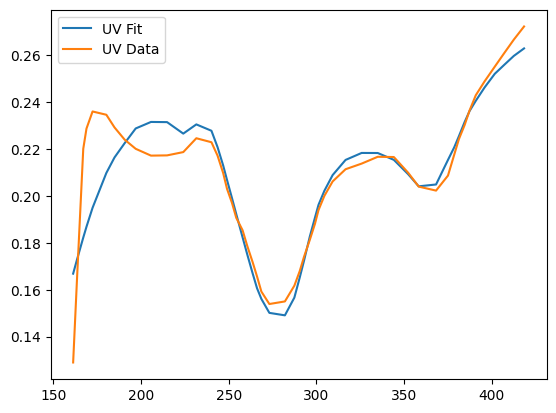

In [11]:
plt.plot(UVx, PDE_allArgs(UVx, theta1=0, **fixedPars_UV, **resDict_UV), label='UV Fit')
plt.plot(UVx, UVy, label='UV Data')

plt.legend()
print("resdict UV:", resDict_UV)

In [12]:
## Now doing Vis fit

fixedPars_Vis = {**resDict_UV, **parBoring}
print("input Vis fixed:", fixedPars_Vis)

floatPars_Vis = {"ph":0.4, "Xpn":1200, "dw_star":7e3}
floatBound_Vis = {key:item for key, item in floatBounds_global_pickFrom.items() if key in floatPars_Vis.keys()}

x0, x0Name = SS.BuildX0(floatPars_Vis, PDE_allArgs)
x0Bounds = SS.BuildX0_bounds(floatBound_Vis, PDE_allArgs)
fitR_Vis = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fixedPars_Vis, dataObj, PDE_allArgs), method='migrad')

print(fitR_Vis)
resDict_Vis = SS.GetResDict(fitR_Vis, x0Name)
resDict_Vis_errors = SS.GetResErrorDict(fitR_Vis, x0Name)
print("score:", fitR_Vis.fun)
print(resDict_Vis)
print(resDict_Vis_errors)


input Vis fixed: {'tOxide': 23.849, 'dp_star': 1.0657, 'pe': 0.7684, 'FF': 0.6, 'quantum': True, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x15d1abcd0>}
  message: Optimization terminated successfully.
  success: True
      fun: 133.0027302477221
        x: [ 4.183e+03  2.272e+04  9.058e-02]
 hess_inv: ┌────┬───────────────────────────────┐
           │    │        x0        x1        x2 │
           ├────┼───────────────────────────────┤
           │ x0 │  5.28e+04    1.52e6   -7.4811 │
           │ x1 │    1.52e6  5.64e+07 -246.9396 │
           │ x2 │   -7.4811 -246.9396   0.00115 │
           └────┴───────────────────────────────┘
     nfev: 238
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 133           

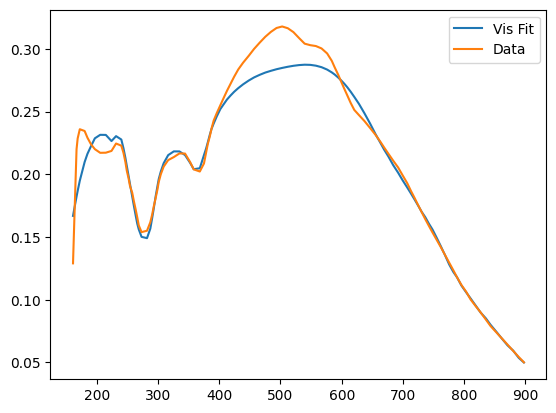

In [13]:
plt.plot(hamx, PDE_allArgs(hamx, theta1=0, **fixedPars_Vis, **resDict_Vis), label='Vis Fit')
plt.plot(hamx, hamy, label='Data')
plt.legend()

plt.show()